In [43]:
import pandas as pd
import matplotlib.pyplot as plt
# Read our processed CSV files
matches = pd.read_csv("../data/processed/matches.csv")
batting = pd.read_csv("../data/processed/batting.csv")
bowling = pd.read_csv("../data/processed/bowling.csv")

# Display the first five rows of each dataset
print("MATCH DATA")
display(matches.head())

print("BATTING DATA")
display(batting.head())

print("BOWLING DATA")
display(bowling.head())

MATCH DATA


,match_id,league,match_date,status,home_team,away_team,home_score,away_score,winner
0,20af648d-dccd-5efc-9c4a-c93766395924,Pakistan Super League,2026-05-03T00:00:00.000Z,finished,Hyderabad Kingsmen,Peshawar Zalmi,129,130,Peshawar Zalmi
1,40cc497b-ea16-564a-9c50-786c13e112b4,Pakistan Super League,2026-05-01T00:00:00.000Z,finished,Hyderabad Kingsmen,Islamabad United,186,184,Hyderabad Kingsmen
2,eca03874-b18c-51e8-85f4-47b4b8e85bef,Pakistan Super League,2026-04-29T00:00:00.000Z,finished,Multan Sultans,Hyderabad Kingsmen,159,162,Hyderabad Kingsmen
3,97805415-d6f4-5057-b4d1-40ea3f1620d8,Pakistan Super League,2026-04-28T00:00:00.000Z,finished,Peshawar Zalmi,Islamabad United,221,151,Peshawar Zalmi
4,03368b7c-7c5e-553b-9ec8-e956210bdb8f,Pakistan Super League,2026-04-26T00:00:00.000Z,finished,Multan Sultans,Islamabad United,192,193,Islamabad United


BATTING DATA


,match_id,innings_number,player_id,player_name,runs,balls,fours,sixes,strike_rate,dismissal_type,dismissal_bowler_id
0,20af648d-dccd-5efc-9c4a-c93766395924,1,4e4b6789-32a0-5e5b-8f4b-a7b61e685781,M Labuschagne,20,12,3,1,166.67,caught,aa7a72af-a8c5-5479-89c3-eaae1fe0d37c
1,20af648d-dccd-5efc-9c4a-c93766395924,1,339cc7f9-4229-55c0-812c-0e4d6fbdd459,Maaz Sadaqat,11,6,1,1,183.33,caught,5b5bdb9f-a010-50c9-a974-f211ae71fb93
2,20af648d-dccd-5efc-9c4a-c93766395924,1,87e027f3-9e15-5d5c-b293-c5b573456f17,Saim Ayub,54,50,5,2,108.00,caught,aa7a72af-a8c5-5479-89c3-eaae1fe0d37c
3,20af648d-dccd-5efc-9c4a-c93766395924,1,1603fdb2-2c14-5bee-8104-47d91af65381,Usman Khan,8,6,1,0,133.33,lbw,a9244d82-db0d-58ae-a367-612ab6edfca8
4,20af648d-dccd-5efc-9c4a-c93766395924,1,8358e6a5-4d08-5d34-8f09-c5b80d522f80,Irfan Khan,1,2,0,0,50.00,run out,NaN


BOWLING DATA


,match_id,innings_number,player_id,player_name,overs,maidens,runs,wickets,economy,wides,no_balls
0,20af648d-dccd-5efc-9c4a-c93766395924,1,1a76875d-cee1-5c8a-986f-c3210be510c7,Iftikhar Ahmed,2.0,0,21,0,10.50,0,0
1,20af648d-dccd-5efc-9c4a-c93766395924,1,5b5bdb9f-a010-50c9-a974-f211ae71fb93,Mohammad Basit,3.0,0,22,1,7.33,0,0
2,20af648d-dccd-5efc-9c4a-c93766395924,1,aa7a72af-a8c5-5479-89c3-eaae1fe0d37c,AM Hardie,4.0,0,27,4,6.75,2,0
3,20af648d-dccd-5efc-9c4a-c93766395924,1,c3859666-15f8-53c4-aedd-047c3efad36b,Nahid Rana,4.0,1,22,2,5.50,0,1
4,20af648d-dccd-5efc-9c4a-c93766395924,1,a9244d82-db0d-58ae-a367-612ab6edfca8,Sufiyan Muqeem,4.0,0,23,1,5.75,1,0


In [22]:
# Check the number of rows and columns
print("Matches shape:", matches.shape)
print("Batting shape:", batting.shape)
print("Bowling shape:", bowling.shape)

# Check the column names
print("\nMatch columns:")
print(matches.columns.tolist())

print("\nBatting columns:")
print(batting.columns.tolist())

print("\nBowling columns:")
print(bowling.columns.tolist())

Matches shape: (5, 9)
Batting shape: (84, 11)
Bowling shape: (60, 11)

Match columns:
['match_id', 'league', 'match_date', 'status', 'home_team', 'away_team', 'home_score', 'away_score', 'winner']

Batting columns:
['match_id', 'innings_number', 'player_id', 'player_name', 'runs', 'balls', 'fours', 'sixes', 'strike_rate', 'dismissal_type', 'dismissal_bowler_id']

Bowling columns:
['match_id', 'innings_number', 'player_id', 'player_name', 'overs', 'maidens', 'runs', 'wickets', 'economy', 'wides', 'no_balls']


In [23]:
# Calculate the total score of each match
matches["total_score"] = (
    matches["home_score"] + matches["away_score"]
)

# Sort matches by total score, from highest to lowest
highest_scoring_matches = matches.sort_values(
    by="total_score",
    ascending=False
)

# Display the match with the highest total score
display(
    highest_scoring_matches[
        ["home_team", "away_team",
         "home_score", "away_score", "total_score"]
    ].head(1)
)

,home_team,away_team,home_score,away_score,total_score
4,Multan Sultans,Islamabad United,192,193,385


Number of matches played each year:


,year,total_matches
0,2026,5


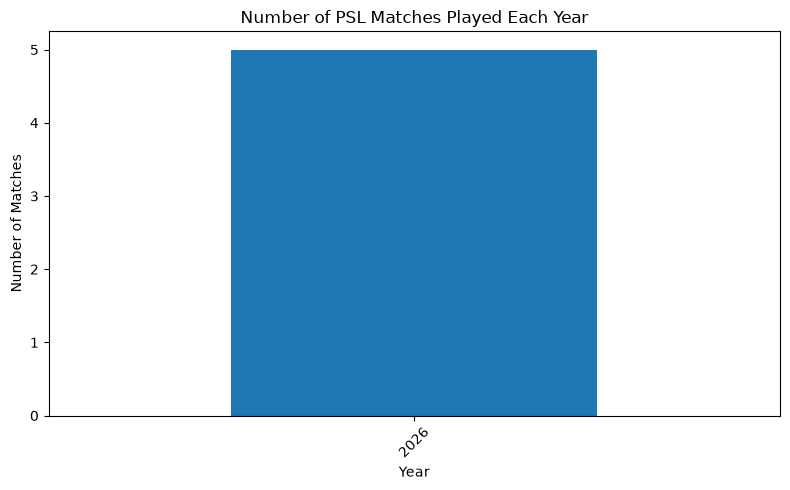

In [42]:
# Count the number of matches played each year

# Convert match_date into a proper date format
matches["match_date"] = pd.to_datetime(
    matches["match_date"], errors="coerce"
)

# Extract the year from each match date
matches["year"] = matches["match_date"].dt.year

# Count matches for each year
matches_per_year = matches.groupby("year").size()

# Display the results
print("Number of matches played each year:")
display(matches_per_year.reset_index(name="total_matches"))

# Create a bar chart
matches_per_year.plot(
    kind="bar",
    figsize=(8, 5),
    title="Number of PSL Matches Played Each Year"
)

plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Graphs and Bar charts By using matplolib

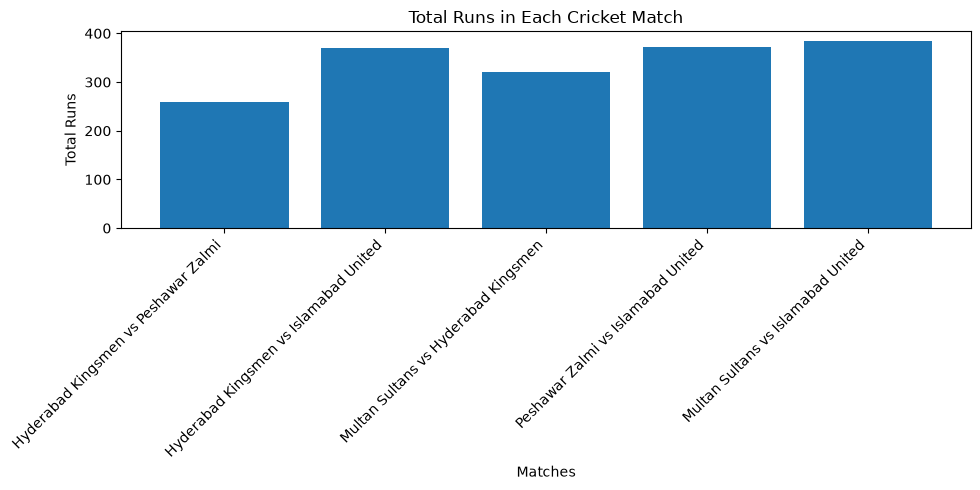

In [24]:
import matplotlib.pyplot as plt

# Create labels for the matches
matches["match_name"] = (
    matches["home_team"] + " vs " + matches["away_team"]
)

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(
    matches["match_name"],
    matches["total_score"]
)

# Add a title and labels
plt.title("Total Runs in Each Cricket Match")
plt.xlabel("Matches")
plt.ylabel("Total Runs")

# Rotate match names to make them easier to read
plt.xticks(rotation=45, ha="right")

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()

In [25]:
# Group records by player and add their runs
player_runs = batting.groupby("player_name")["runs"].sum()

# Sort players from highest runs to lowest
top_players = player_runs.sort_values(ascending=False)

# Display the top 5 players
print("Top 5 run scorers:")
display(top_players.head(5))

Top 5 run scorers:


player_name
Usman Khan     133
MS Chapman     116
Shan Masood    113
Saim Ayub      107
Babar Azam     103
Name: runs, dtype: int64

Bar chart for players

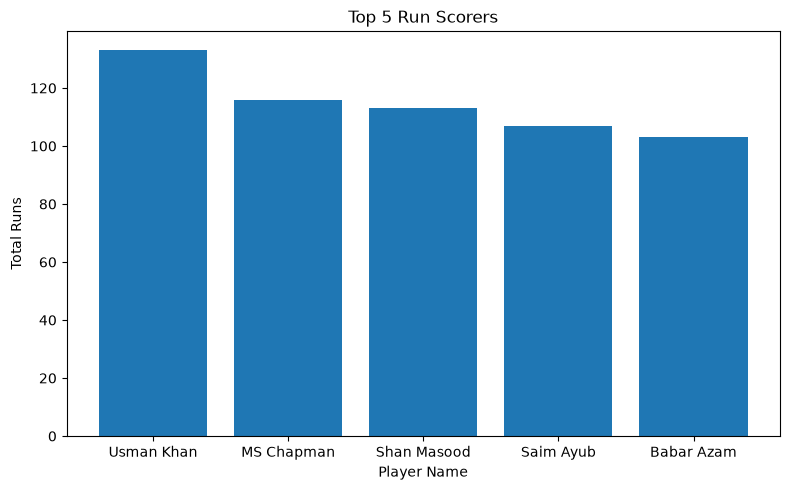

In [26]:
import matplotlib.pyplot as plt

# Select the top 5 players
top_5_players = top_players.head(5)

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    top_5_players.index,
    top_5_players.values
)

# Add the title and labels
plt.title("Top 5 Run Scorers")
plt.xlabel("Player Name")
plt.ylabel("Total Runs")

# Display the graph
plt.tight_layout()
plt.show()

In [27]:
# Group bowling records by player and add their wickets
player_wickets = bowling.groupby("player_name")["wickets"].sum()

# Sort players from most wickets to fewest
top_bowlers = player_wickets.sort_values(ascending=False)

# Display the top 5 wicket-takers
print("Top 5 wicket-takers:")
display(top_bowlers.head(5))

Top 5 wicket-takers:


player_name
AM Hardie       7
Mohammad Ali    7
Hunain Shah     5
Shadab Khan     4
Akif Javed      4
Name: wickets, dtype: int64

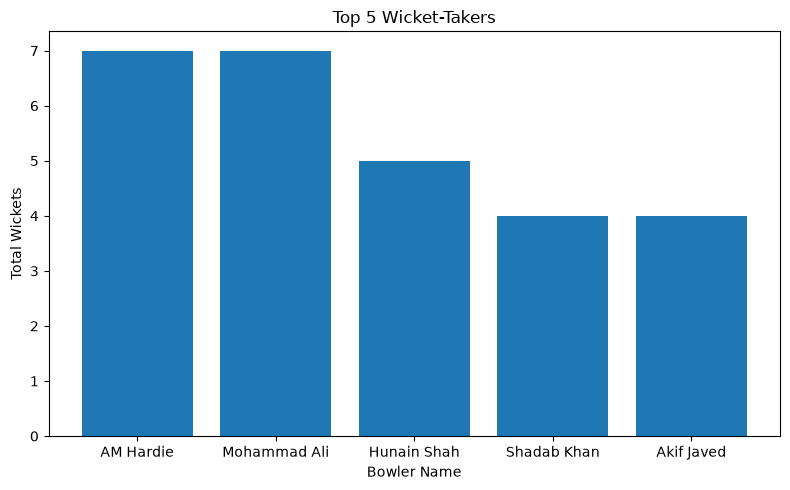

In [28]:
import matplotlib.pyplot as plt

# Select the top 5 wicket-takers
top_5_bowlers = top_bowlers.head(5)

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    top_5_bowlers.index,
    top_5_bowlers.values
)

# Add the title and labels
plt.title("Top 5 Wicket-Takers")
plt.xlabel("Bowler Name")
plt.ylabel("Total Wickets")

# Display the graph
plt.tight_layout()
plt.show()

In [29]:
# Count how many times each team appears as the winner
team_wins = matches["winner"].value_counts()

# Display the results
print("Team Wins:")
display(team_wins)

Team Wins:


winner
Peshawar Zalmi        2
Hyderabad Kingsmen    2
Islamabad United      1
Name: count, dtype: int64

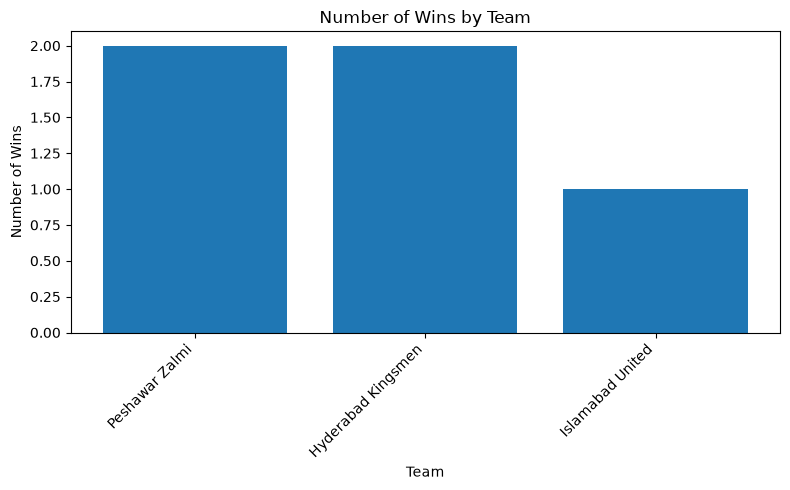

In [30]:
import matplotlib.pyplot as plt

# Create a bar chart of team wins
plt.figure(figsize=(8, 5))

plt.bar(
    team_wins.index,
    team_wins.values
)

# Add title and axis labels
plt.title("Number of Wins by Team")
plt.xlabel("Team")
plt.ylabel("Number of Wins")

# Rotate team names for readability
plt.xticks(rotation=45, ha="right")

# Display the graph
plt.tight_layout()
plt.show()

In [31]:
# Group batting records by player
player_batting = batting.groupby("player_name").agg(
    total_runs=("runs", "sum"),
    total_balls=("balls", "sum")
)

# Calculate overall strike rate
player_batting["strike_rate"] = (
    player_batting["total_runs"]
    / player_batting["total_balls"]
    * 100
)

# Sort players by strike rate
top_strike_rates = player_batting.sort_values(
    by="strike_rate",
    ascending=False
)

# Display the top 5 players
display(top_strike_rates.head(5))

,total_runs,total_balls,strike_rate
player_name,,,
Khurram Shahzad,4,1,400.000000
Mohammad Wasim,26,9,288.888889
Mohammad Haris,41,19,215.789474
Haider Ali,52,26,200.000000
CJ Green,34,18,188.888889


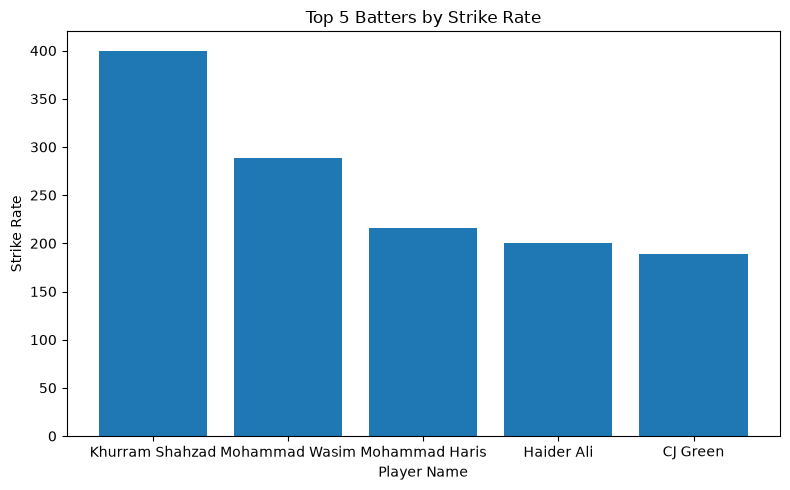

In [32]:
import matplotlib.pyplot as plt

# Select the top 5 players by strike rate
top_5_strike_rates = top_strike_rates.head(5)

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    top_5_strike_rates.index,
    top_5_strike_rates["strike_rate"]
)

# Add the title and labels
plt.title("Top 5 Batters by Strike Rate")
plt.xlabel("Player Name")
plt.ylabel("Strike Rate")

# Display the graph
plt.tight_layout()
plt.show()

In [40]:

# Analyze strike rates for players who faced at least 10 balls

# Load the batting data
batting_df = pd.read_csv("../data/processed/batting.csv")

# Group each player's runs and balls across the selected matches
player_stats = batting_df.groupby("player_name").agg(
    total_runs=("runs", "sum"),
    total_balls=("balls", "sum")
).reset_index()

# Keep players who faced at least 10 balls
player_stats = player_stats[player_stats["total_balls"] >= 10].copy()

# Calculate overall strike rate
player_stats["strike_rate"] = (
    player_stats["total_runs"] / player_stats["total_balls"]
) * 100

# Display the top 10 players by strike rate
top_strike_rates = player_stats.sort_values(
    by="strike_rate", ascending=False
).head(10)

display(top_strike_rates)


,player_name,total_runs,total_balls,strike_rate
27,Mohammad Haris,41,19,215.789474
13,Haider Ali,52,26,200.000000
7,CJ Green,34,18,188.888889
42,Usman Khan,133,71,187.323944
25,Maaz Sadaqat,75,43,174.418605
6,Babar Azam,103,60,171.666667
24,MS Chapman,116,68,170.588235
22,MDKJ Perera,38,23,165.217391
39,Sameer Minhas,51,31,164.516129
1,AM Hardie,76,49,155.102041


In [33]:
# Copy bowling data so the original data stays unchanged
bowling_analysis = bowling.copy()

# Convert overs notation into completed overs and extra balls
bowling_analysis["completed_overs"] = bowling_analysis["overs"].apply(
    lambda overs: int(float(overs))
)

bowling_analysis["extra_balls"] = bowling_analysis["overs"].apply(
    lambda overs: round((float(overs) - int(float(overs))) * 10)
)

# Calculate total balls bowled in each record
bowling_analysis["total_balls"] = (
    bowling_analysis["completed_overs"] * 6
    + bowling_analysis["extra_balls"]
)

# Group bowling records by player
player_bowling = bowling_analysis.groupby("player_name").agg(
    total_runs_conceded=("runs", "sum"),
    total_balls=("total_balls", "sum")
)

# Calculate overall economy rate
player_bowling["economy_rate"] = (
    player_bowling["total_runs_conceded"]
    / player_bowling["total_balls"]
    * 6
)

# Sort from lowest economy rate to highest
most_economical = player_bowling.sort_values(
    by="economy_rate",
    ascending=True
)

# Display the five lowest economy rates
display(most_economical.head(5))

,total_runs_conceded,total_balls,economy_rate
player_name,,,
Nahid Rana,22,24,5.500000
Sufiyan Muqeem,48,48,6.000000
Mohammad Basit,41,40,6.150000
AM Hardie,51,48,6.375000
Saim Ayub,67,54,7.444444


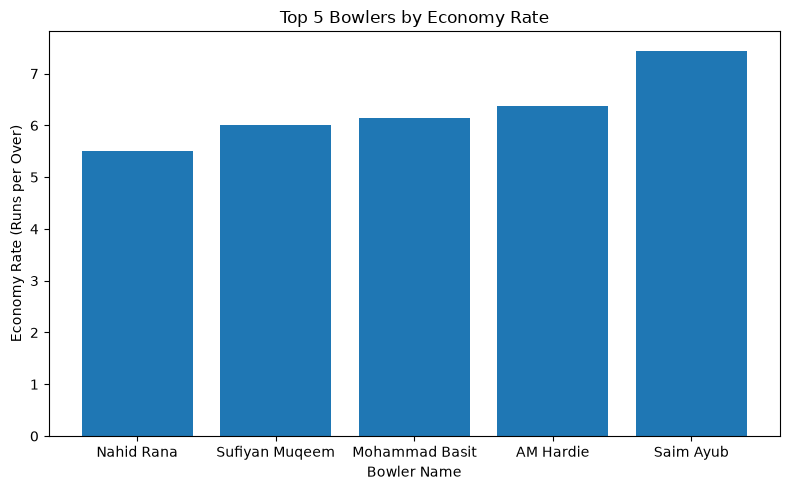

In [34]:
import matplotlib.pyplot as plt

# Select the five lowest economy rates
top_5_economical = most_economical.head(5)

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    top_5_economical.index,
    top_5_economical["economy_rate"]
)

# Add the title and labels
plt.title("Top 5 Bowlers by Economy Rate")
plt.xlabel("Bowler Name")
plt.ylabel("Economy Rate (Runs per Over)")

# Display the graph
plt.tight_layout()
plt.show()

In [35]:
# Group batting records by player and total their boundaries
player_boundaries = batting.groupby("player_name").agg(
    total_fours=("fours", "sum"),
    total_sixes=("sixes", "sum")
)

# Calculate total boundaries
player_boundaries["total_boundaries"] = (
    player_boundaries["total_fours"]
    + player_boundaries["total_sixes"]
)

# Sort from most boundaries to fewest
player_boundaries = player_boundaries.sort_values(
    by="total_boundaries",
    ascending=False
)

# Display the top 5 batters
display(player_boundaries.head(5))

,total_fours,total_sixes,total_boundaries
player_name,,,
Usman Khan,19,3,22
MS Chapman,9,8,17
Babar Azam,12,4,16
Saim Ayub,12,2,14
Shan Masood,7,6,13


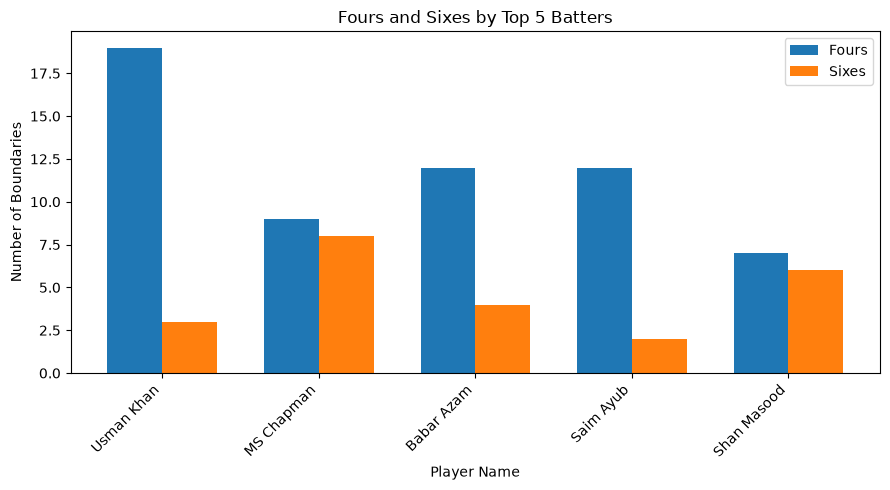

In [36]:
import matplotlib.pyplot as plt

# Select the top 5 players
top_5_boundaries = player_boundaries.head(5)

# Create positions for the bars
positions = range(len(top_5_boundaries))
bar_width = 0.35

# Create the chart
plt.figure(figsize=(9, 5))

plt.bar(
    [p - bar_width / 2 for p in positions],
    top_5_boundaries["total_fours"],
    width=bar_width,
    label="Fours"
)

plt.bar(
    [p + bar_width / 2 for p in positions],
    top_5_boundaries["total_sixes"],
    width=bar_width,
    label="Sixes"
)

# Add the title, labels, and legend
plt.title("Fours and Sixes by Top 5 Batters")
plt.xlabel("Player Name")
plt.ylabel("Number of Boundaries")
plt.xticks(positions, top_5_boundaries.index, rotation=45, ha="right")
plt.legend()

# Display the chart
plt.tight_layout()
plt.show()


In [37]:
# Select the important match details
match_details = matches[
    [
        "match_date",
        "home_team",
        "away_team",
        "home_score",
        "away_score",
        "winner",
        "total_score"
    ]
]

# Display all five matches
display(match_details)

,match_date,home_team,away_team,home_score,away_score,winner,total_score
0,2026-05-03T00:00:00.000Z,Hyderabad Kingsmen,Peshawar Zalmi,129,130,Peshawar Zalmi,259
1,2026-05-01T00:00:00.000Z,Hyderabad Kingsmen,Islamabad United,186,184,Hyderabad Kingsmen,370
2,2026-04-29T00:00:00.000Z,Multan Sultans,Hyderabad Kingsmen,159,162,Hyderabad Kingsmen,321
3,2026-04-28T00:00:00.000Z,Peshawar Zalmi,Islamabad United,221,151,Peshawar Zalmi,372
4,2026-04-26T00:00:00.000Z,Multan Sultans,Islamabad United,192,193,Islamabad United,385


In [38]:
# Count missing values in each dataset

print("Missing values in match data:")
display(matches.isnull().sum())

print("Missing values in batting data:")
display(batting.isnull().sum())

print("Missing values in bowling data:")
display(bowling.isnull().sum())

Missing values in match data:


match_id       0
league         0
match_date     0
status         0
home_team      0
away_team      0
home_score     0
away_score     0
winner         0
total_score    0
match_name     0
dtype: int64

Missing values in batting data:


match_id                0
innings_number          0
player_id               0
player_name             0
runs                    0
balls                   0
fours                   0
sixes                   0
strike_rate             0
dismissal_type         16
dismissal_bowler_id    21
dtype: int64

Missing values in bowling data:


match_id          0
innings_number    0
player_id         0
player_name       0
overs             0
maidens           0
runs              0
wickets           0
economy           0
wides             0
no_balls          0
dtype: int64

In [39]:
# Count duplicate rows in each dataset

print("Duplicate match rows:", matches.duplicated().sum())

print("Duplicate batting rows:", batting.duplicated().sum())

print("Duplicate bowling rows:", bowling.duplicated().sum())

Duplicate match rows: 0
Duplicate batting rows: 0
Duplicate bowling rows: 0
